SAMUDRAGUPTA JEJURKAR - 23102C0064

# Lab Problem Statement 6: Statistical Analysis of Physical Characteristics of Palmer Penguins

Complete R analysis covering descriptive statistics, hypothesis testing, t-test, Cohen's d, one-way ANOVA, Tukey HSD, Kruskal-Wallis, two-way ANOVA, flipper-length analysis, and visualizations.

In [1]:
# Install and load packages
install.packages(c('tidyverse','palmerpenguins','moments','car','effsize'), repos='https://cloud.r-project.org')
library(tidyverse)
library(palmerpenguins)
library(moments)
library(car)
library(effsize)


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘palmerpenguins’


The following objects are ma

In [2]:
# Load and inspect Palmer Penguins dataset
data('penguins')
head(penguins)
str(penguins)
dim(penguins)
summary(penguins)
colSums(is.na(penguins))

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,NA,NA,NA,NA,NA,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007


tibble [344 × 8] (S3: tbl_df/tbl/data.frame)
 $ species          : Factor w/ 3 levels "Adelie","Chinstrap",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ island           : Factor w/ 3 levels "Biscoe","Dream",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ bill_length_mm   : num [1:344] 39.1 39.5 40.3 NA 36.7 39.3 38.9 39.2 34.1 42 ...
 $ bill_depth_mm    : num [1:344] 18.7 17.4 18 NA 19.3 20.6 17.8 19.6 18.1 20.2 ...
 $ flipper_length_mm: int [1:344] 181 186 195 NA 193 190 181 195 193 190 ...
 $ body_mass_g      : int [1:344] 3750 3800 3250 NA 3450 3650 3625 4675 3475 4250 ...
 $ sex              : Factor w/ 2 levels "female","male": 2 1 1 NA 1 2 1 2 NA NA ...
 $ year             : int [1:344] 2007 2007 2007 2007 2007 2007 2007 2007 2007 2007 ...


[1] 344   8

      species          island    bill_length_mm  bill_depth_mm  
 Adelie   :152   Biscoe   :168   Min.   :32.10   Min.   :13.10  
 Chinstrap: 68   Dream    :124   1st Qu.:39.23   1st Qu.:15.60  
 Gentoo   :124   Torgersen: 52   Median :44.45   Median :17.30  
                                 Mean   :43.92   Mean   :17.15  
                                 3rd Qu.:48.50   3rd Qu.:18.70  
                                 Max.   :59.60   Max.   :21.50  
                                 NAs    :2       NAs    :2      
 flipper_length_mm  body_mass_g       sex           year     
 Min.   :172.0     Min.   :2700   female:165   Min.   :2007  
 1st Qu.:190.0     1st Qu.:3550   male  :168   1st Qu.:2007  
 Median :197.0     Median :4050   NAs   : 11   Median :2008  
 Mean   :200.9     Mean   :4202                Mean   :2008  
 3rd Qu.:213.0     3rd Qu.:4750                3rd Qu.:2009  
 Max.   :231.0     Max.   :6300                Max.   :2009  
 NAs    :2         NAs    :2                  

species            island    bill_length_mm     bill_depth_mm 
                0                 0                 2                 2 
flipper_length_mm       body_mass_g               sex              year 
                2                 2                11                 0

In [3]:
# Clean data
penguins_clean <- penguins %>%
  drop_na(body_mass_g, flipper_length_mm, species, sex)
nrow(penguins_clean)


[1] 333

## 1. Descriptive Statistical Analysis

In [4]:
# Overall body-mass descriptive statistics
body_mass_stats <- penguins_clean %>%
  summarise(
    Mean = mean(body_mass_g),
    Median = median(body_mass_g),
    Minimum = min(body_mass_g),
    Maximum = max(body_mass_g),
    Variance = var(body_mass_g),
    SD = sd(body_mass_g),
    Q1 = quantile(body_mass_g, 0.25),
    Q3 = quantile(body_mass_g, 0.75),
    IQR = IQR(body_mass_g),
    Skewness = skewness(body_mass_g),
    Kurtosis = kurtosis(body_mass_g)
  )
body_mass_stats

Mean,Median,Minimum,Maximum,Variance,SD,Q1,Q3,IQR,Skewness,Kurtosis
<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4207.057,4050,2700,6300,648372.5,805.2158,3550,4775,1225,0.4701162,2.259514


In [5]:
# Species-wise descriptive statistics
species_stats <- penguins_clean %>%
  group_by(species) %>%
  summarise(
    N = n(), Mean = mean(body_mass_g), Median = median(body_mass_g),
    Minimum = min(body_mass_g), Maximum = max(body_mass_g),
    Variance = var(body_mass_g), SD = sd(body_mass_g),
    Q1 = quantile(body_mass_g, .25), Q3 = quantile(body_mass_g, .75),
    IQR = IQR(body_mass_g), Skewness = skewness(body_mass_g),
    Kurtosis = kurtosis(body_mass_g)
  )
species_stats

species,N,Mean,Median,Minimum,Maximum,Variance,SD,Q1,Q3,IQR,Skewness,Kurtosis
<fct>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Adelie,146,3706.164,3700,2850,4775,210332.4,458.6201,3362.5,4000,637.5,0.2770077,2.411479
Chinstrap,68,3733.088,3700,2700,4800,147713.5,384.3351,3487.5,3950,462.5,0.2419413,3.463681
Gentoo,119,5092.437,5050,3950,6300,251478.3,501.4762,4700.0,5500,800.0,0.0449965,2.242850


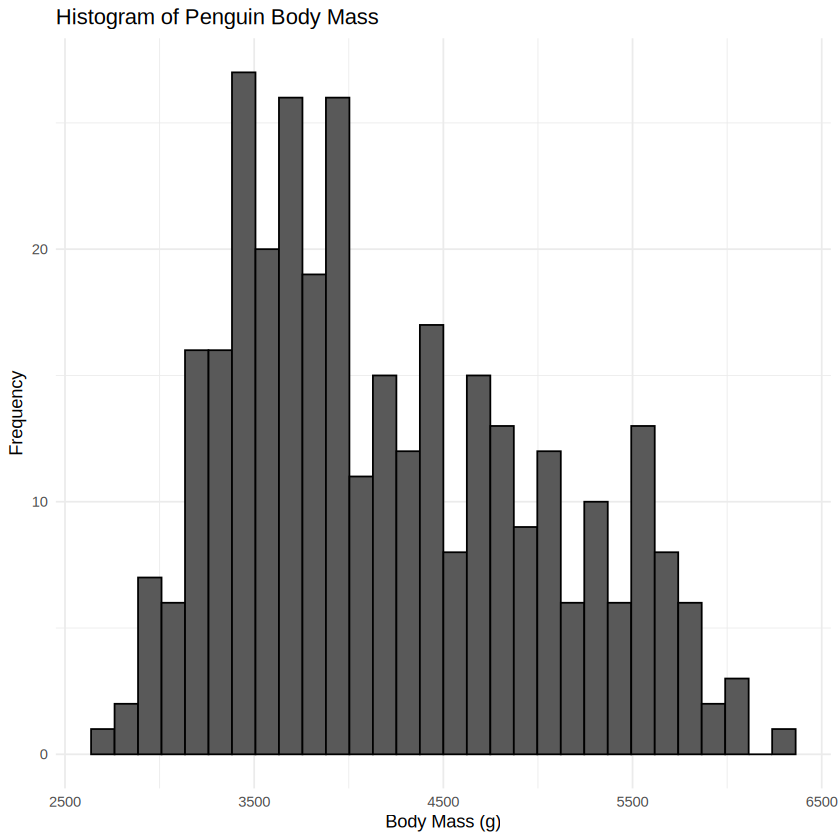

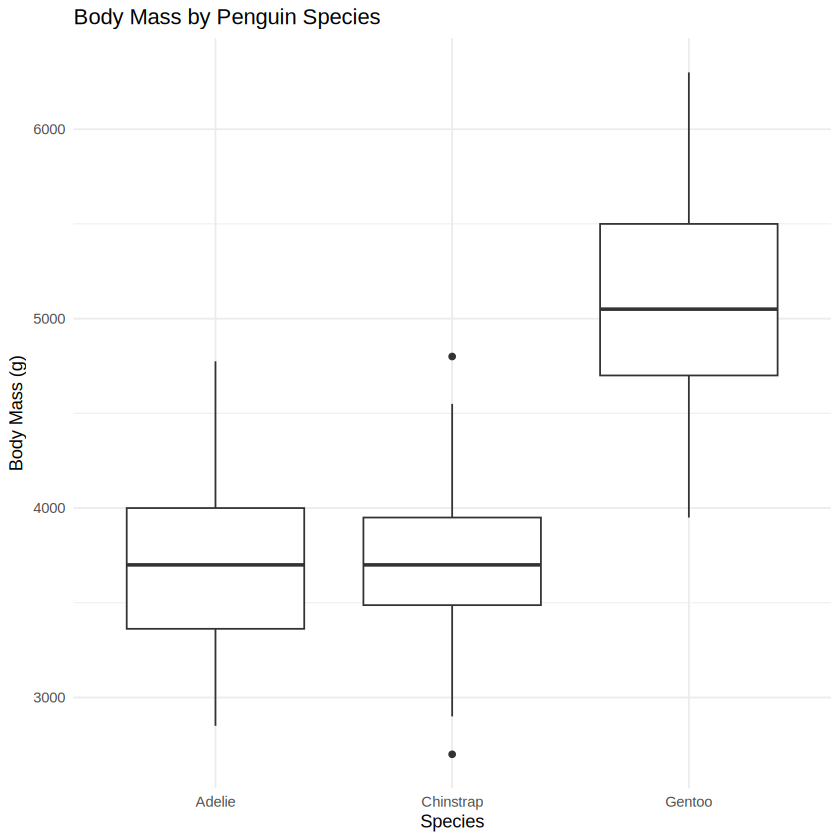

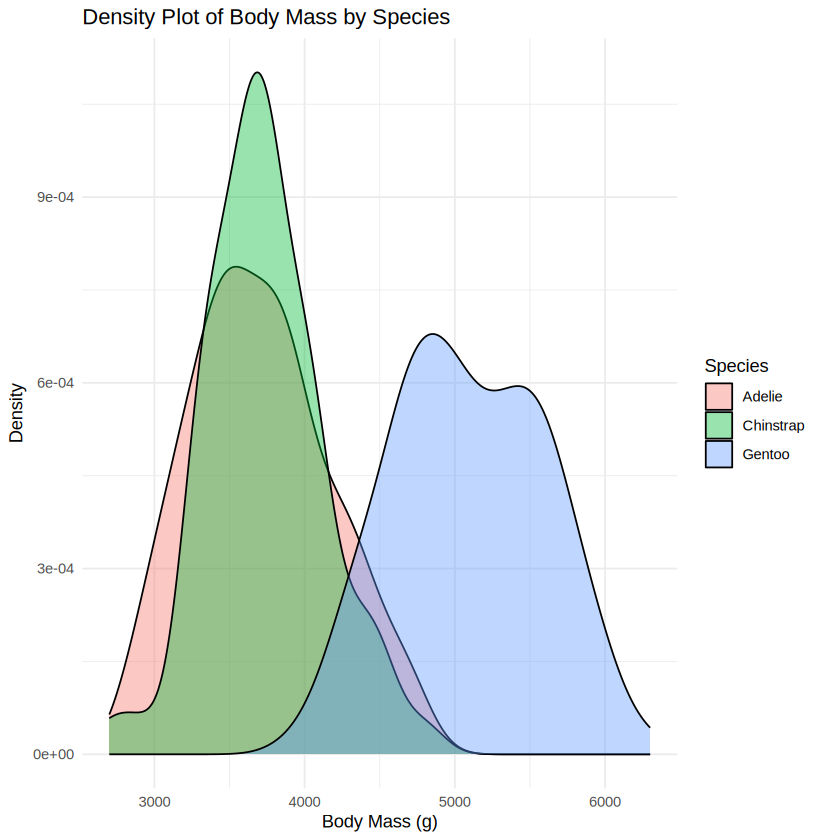

In [6]:
# Histogram
ggplot(penguins_clean, aes(x=body_mass_g)) +
  geom_histogram(bins=30, color='black') +
  labs(title='Histogram of Penguin Body Mass', x='Body Mass (g)', y='Frequency') +
  theme_minimal()

# Species-wise boxplot
ggplot(penguins_clean, aes(x=species, y=body_mass_g)) +
  geom_boxplot() +
  labs(title='Body Mass by Penguin Species', x='Species', y='Body Mass (g)') +
  theme_minimal()

# Density plot
ggplot(penguins_clean, aes(x=body_mass_g, fill=species)) +
  geom_density(alpha=.4) +
  labs(title='Density Plot of Body Mass by Species', x='Body Mass (g)', y='Density', fill='Species') +
  theme_minimal()

## 2. Male vs Female Body Mass: Hypothesis Testing


	Shapiro-Wilk normality test

data:  male_mass
W = 0.92504, p-value = 1.227e-07



	Shapiro-Wilk normality test

data:  female_mass
W = 0.91931, p-value = 6.155e-08


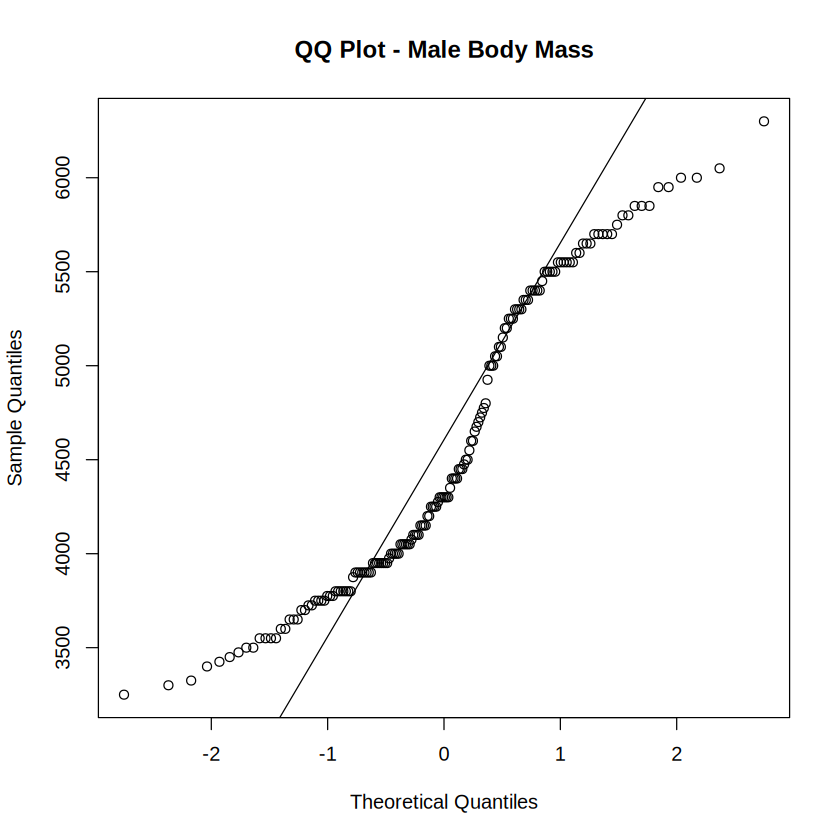


	Welch Two Sample t-test

data:  body_mass_g by sex
t = -8.5545, df = 323.9, p-value = 4.794e-16
alternative hypothesis: true difference in means between group female and group male is not equal to 0
95 percent confidence interval:
 -840.5783 -526.2453
sample estimates:
mean in group female   mean in group male 
            3862.273             4545.685 



Cohen's d

d estimate: -0.9362048 (large)
95 percent confidence interval:
     lower      upper 
-1.1633158 -0.7090938 


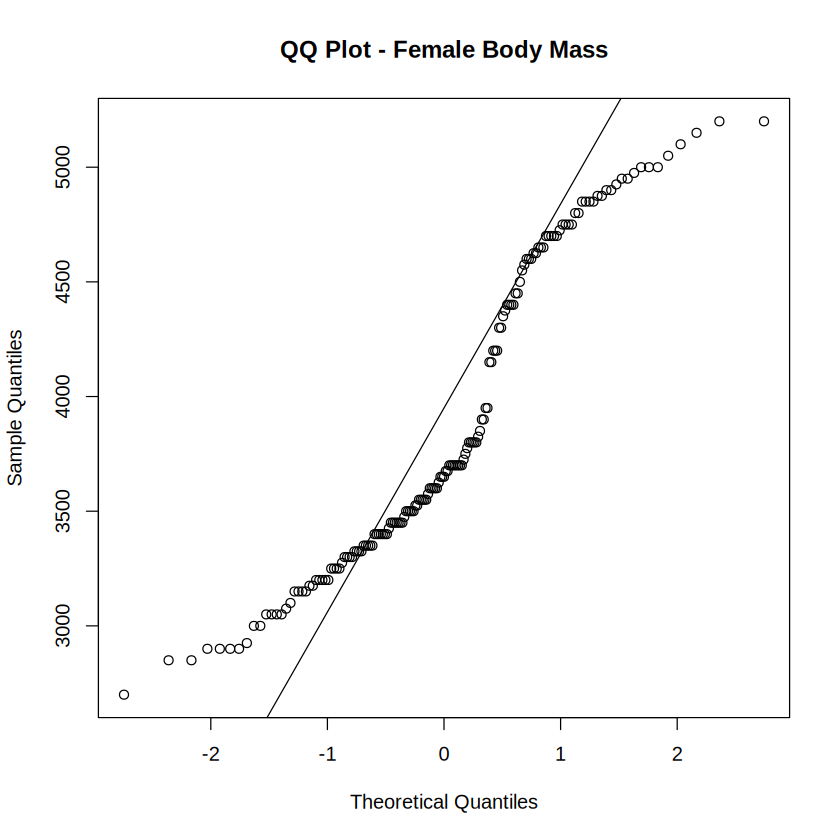

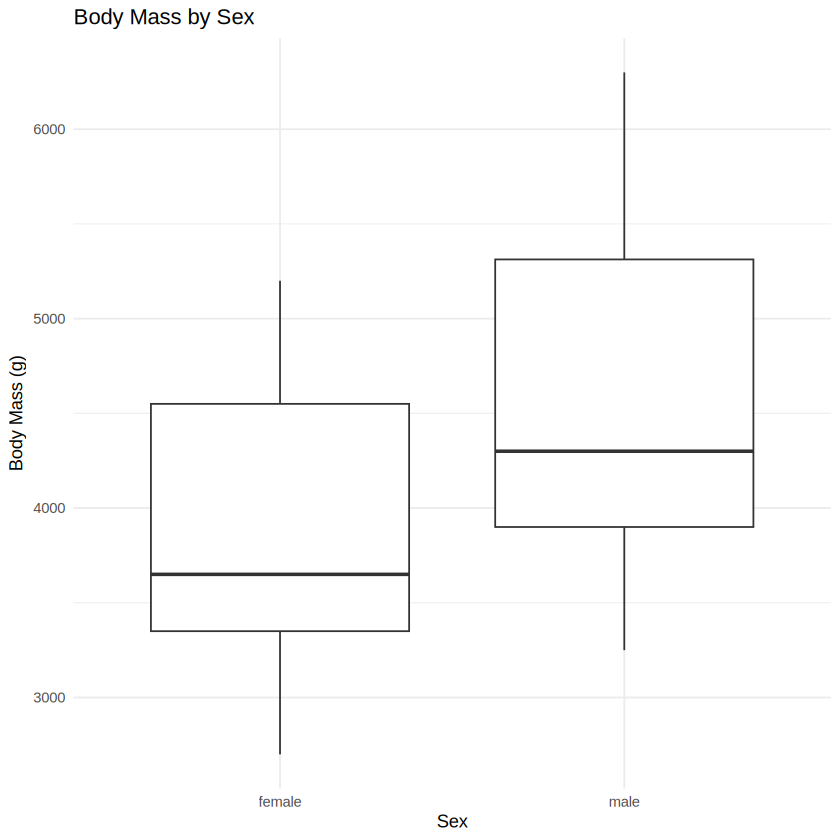

In [7]:
# H0: Male and female penguins have equal mean body mass.
# H1: Male and female penguins have different mean body mass.
male_mass <- penguins_clean %>% filter(sex=='male') %>% pull(body_mass_g)
female_mass <- penguins_clean %>% filter(sex=='female') %>% pull(body_mass_g)

shapiro.test(male_mass)
shapiro.test(female_mass)

qqnorm(male_mass, main='QQ Plot - Male Body Mass'); qqline(male_mass)
qqnorm(female_mass, main='QQ Plot - Female Body Mass'); qqline(female_mass)

t_test_result <- t.test(body_mass_g ~ sex, data=penguins_clean, var.equal=FALSE)
t_test_result

cohen_d <- cohen.d(body_mass_g ~ sex, data=penguins_clean, hedges.correction=FALSE)
cohen_d

ggplot(penguins_clean, aes(x=sex, y=body_mass_g)) +
  geom_boxplot() +
  labs(title='Body Mass by Sex', x='Sex', y='Body Mass (g)') + theme_minimal()


## 3. One-Way ANOVA: Body Mass by Species

species,Shapiro_p_value
<fct>,<dbl>
Adelie,0.0423224
Chinstrap,0.5605082
Gentoo,0.2605247


,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,2,5.134899,0.006367054
,330,NA,NA


             Df    Sum Sq  Mean Sq F value Pr(>F)    
species       2 145190219 72595110   341.9 <2e-16 ***
Residuals   330  70069447   212332                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = body_mass_g ~ species, data = penguins_clean)

$species
                       diff       lwr       upr    p adj
Chinstrap-Adelie   26.92385 -132.3528  186.2005 0.916431
Gentoo-Adelie    1386.27259 1252.2897 1520.2554 0.000000
Gentoo-Chinstrap 1359.34874 1194.4304 1524.2671 0.000000


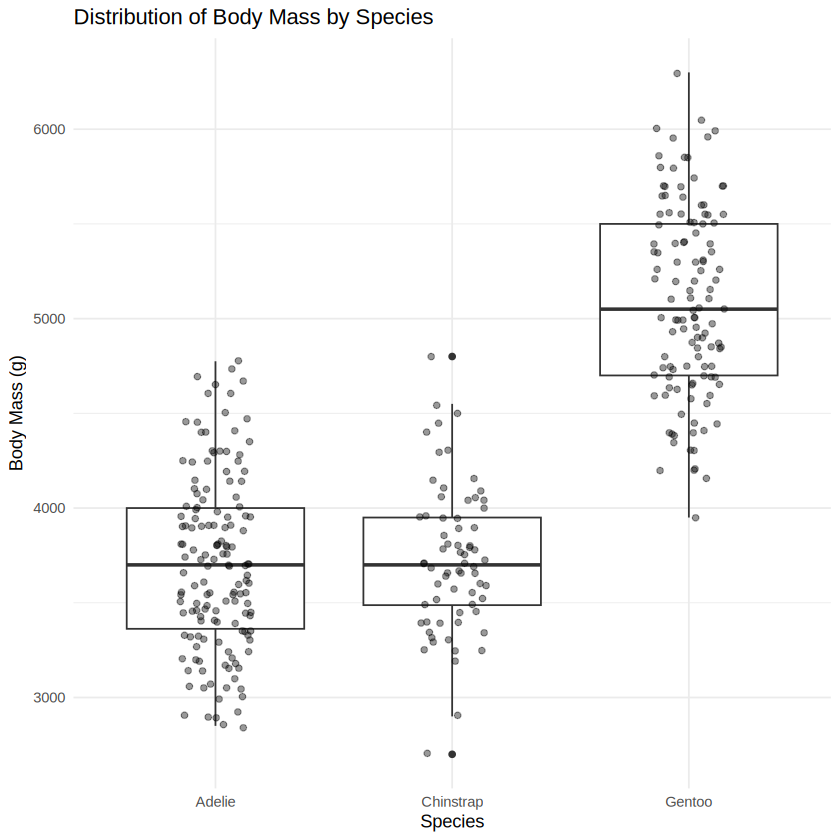

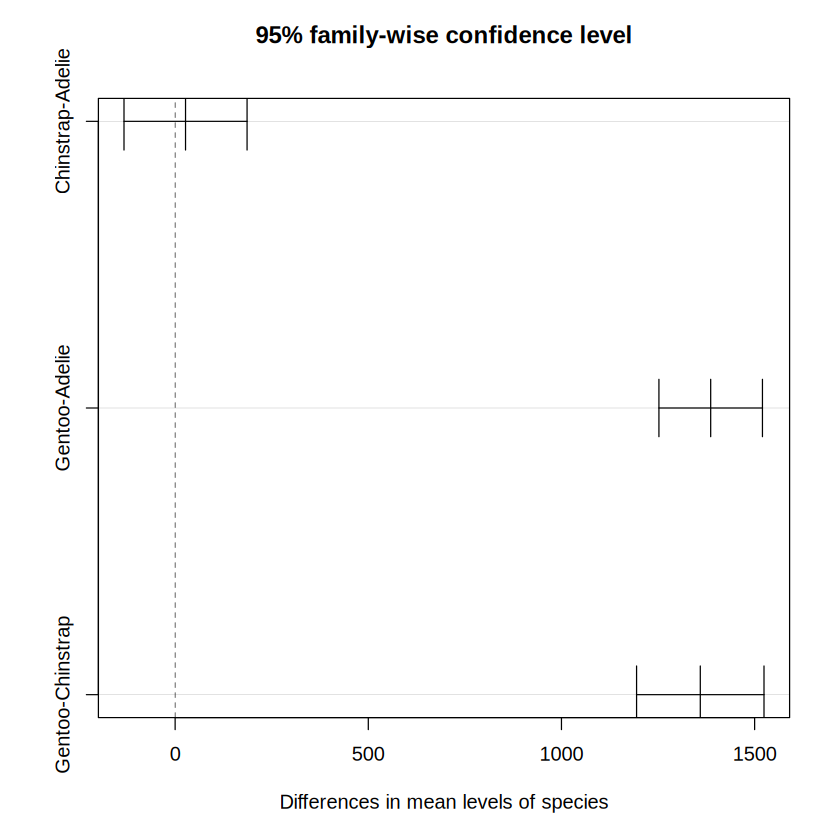

In [8]:
ggplot(penguins_clean, aes(x=species, y=body_mass_g)) +
  geom_boxplot() + geom_jitter(width=.15, alpha=.4) +
  labs(title='Distribution of Body Mass by Species', x='Species', y='Body Mass (g)') + theme_minimal()

# Shapiro-Wilk by species
penguins_clean %>% group_by(species) %>%
  summarise(Shapiro_p_value=shapiro.test(body_mass_g)$p.value)

# Levene's test
levene_result <- leveneTest(body_mass_g ~ species, data=penguins_clean)
levene_result

# One-way ANOVA
anova_model <- aov(body_mass_g ~ species, data=penguins_clean)
summary(anova_model)

# Tukey HSD
tukey_result <- TukeyHSD(anova_model)
tukey_result
plot(tukey_result)


## 4. Kruskal-Wallis Non-Parametric Test

In [9]:
kruskal_result <- kruskal.test(body_mass_g ~ species, data=penguins_clean)
kruskal_result

anova_p <- summary(anova_model)[[1]][['Pr(>F)']][1]
kw_p <- kruskal_result$p.value
cat('ANOVA p-value:', anova_p, '\n')
cat('Kruskal-Wallis p-value:', kw_p, '\n')



	Kruskal-Wallis rank sum test

data:  body_mass_g by species
Kruskal-Wallis chi-squared = 212.09, df = 2, p-value < 2.2e-16


ANOVA p-value: 3.744505e-81 
Kruskal-Wallis p-value: 8.836877e-47 


## 5. Two-Way ANOVA: Species × Sex

             Df    Sum Sq  Mean Sq F value   Pr(>F)    
species       2 145190219 72595110 758.358  < 2e-16 ***
sex           1  37090262 37090262 387.460  < 2e-16 ***
species:sex   2   1676557   838278   8.757 0.000197 ***
Residuals   327  31302628    95727                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
species,2,145190219,72595109.56,758.358072,1.540207e-123
sex,1,37090262,37090261.78,387.459976,1.902273e-57
species:sex,2,1676557,838278.37,8.756997,1.973489e-04
Residuals,327,31302628,95726.69,NA,NA


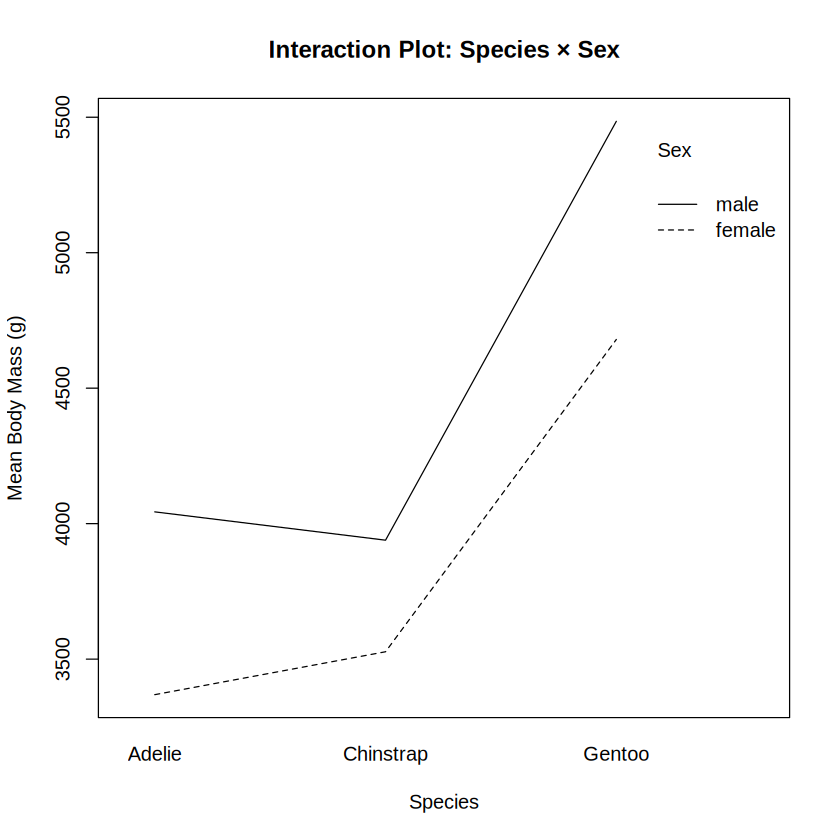

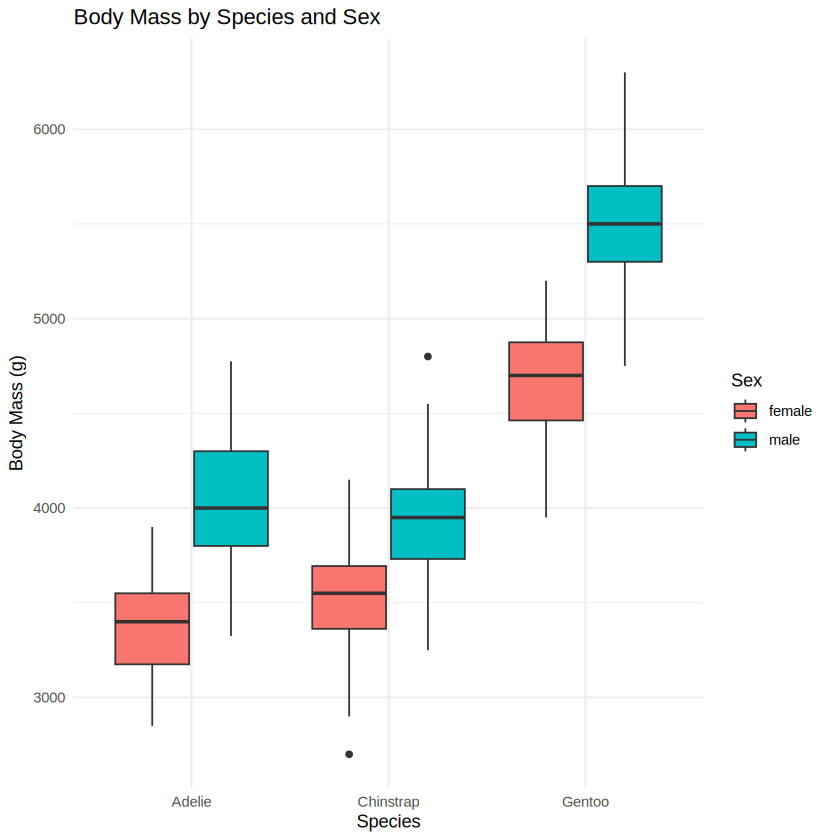

In [10]:
two_way_model <- aov(body_mass_g ~ species * sex, data=penguins_clean)
two_way_anova <- anova(two_way_model)
summary(two_way_model)
two_way_anova

interaction.plot(
  x.factor=penguins_clean$species,
  trace.factor=penguins_clean$sex,
  response=penguins_clean$body_mass_g,
  fun=mean,
  xlab='Species', ylab='Mean Body Mass (g)', trace.label='Sex',
  main='Interaction Plot: Species × Sex'
)

ggplot(penguins_clean, aes(x=species, y=body_mass_g, fill=sex)) +
  geom_boxplot(position=position_dodge(width=.8)) +
  labs(title='Body Mass by Species and Sex', x='Species', y='Body Mass (g)', fill='Sex') +
  theme_minimal()

## 6. Additional Analysis: Flipper Length

species,N,Mean,Median,SD,Minimum,Maximum,IQR
<fct>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
Adelie,146,190.1027,190,6.521825,172,210,9.0
Chinstrap,68,195.8235,196,7.131894,178,212,10.0
Gentoo,119,217.2353,216,6.585431,203,231,9.5


             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  50526   25263   567.4 <2e-16 ***
Residuals   330  14693      45                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = flipper_length_mm ~ species, data = penguins_clean)

$species
                     diff       lwr       upr p adj
Chinstrap-Adelie  5.72079  3.414364  8.027215     0
Gentoo-Adelie    27.13255 25.192399 29.072709     0
Gentoo-Chinstrap 21.41176 19.023644 23.799885     0



	Kruskal-Wallis rank sum test

data:  flipper_length_mm by species
Kruskal-Wallis chi-squared = 237.35, df = 2, p-value < 2.2e-16


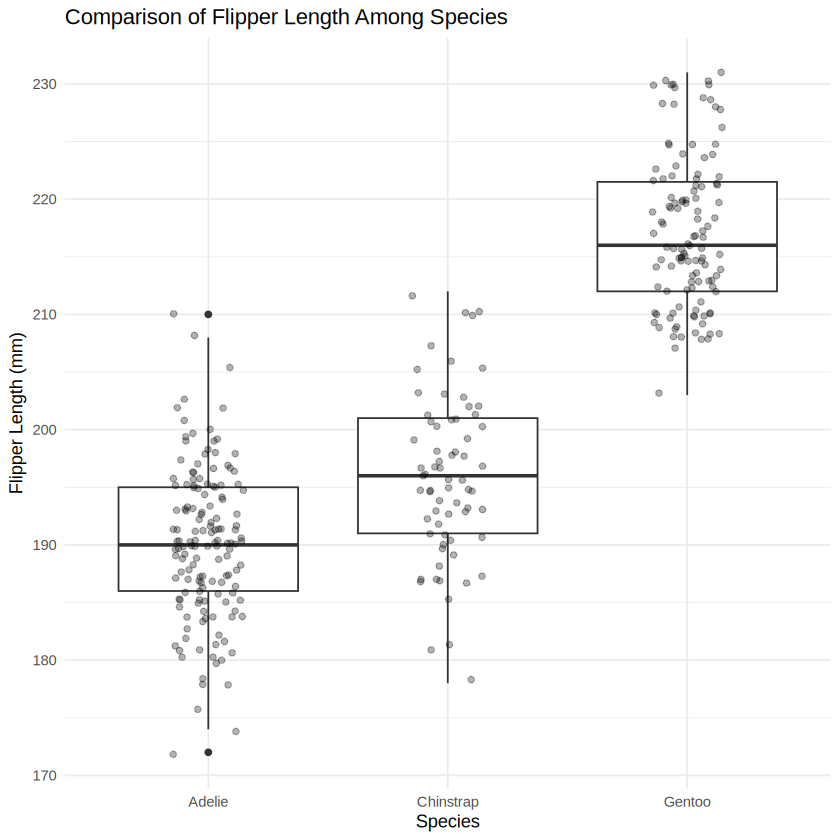

In [11]:
flipper_stats <- penguins_clean %>% group_by(species) %>% summarise(
  N=n(), Mean=mean(flipper_length_mm), Median=median(flipper_length_mm),
  SD=sd(flipper_length_mm), Minimum=min(flipper_length_mm),
  Maximum=max(flipper_length_mm), IQR=IQR(flipper_length_mm)
)
flipper_stats

ggplot(penguins_clean, aes(x=species, y=flipper_length_mm)) +
  geom_boxplot() + geom_jitter(width=.15, alpha=.3) +
  labs(title='Comparison of Flipper Length Among Species', x='Species', y='Flipper Length (mm)') +
  theme_minimal()

flipper_anova <- aov(flipper_length_mm ~ species, data=penguins_clean)
summary(flipper_anova)
flipper_tukey <- TukeyHSD(flipper_anova)
flipper_tukey
flipper_kruskal <- kruskal.test(flipper_length_mm ~ species, data=penguins_clean)
flipper_kruskal

## 7. Final Summary

In [12]:
cat('============================================\n')
cat('PALMER PENGUINS STATISTICAL ANALYSIS\n')
cat('============================================\n\n')
cat('Number of observations:', nrow(penguins_clean), '\n\n')
cat('Male vs Female t-test p-value:', t_test_result$p.value, '\n')
cat('95% CI:', t_test_result$conf.int[1], 'to', t_test_result$conf.int[2], '\n')
cat('One-Way ANOVA p-value:', anova_p, '\n')
cat('Kruskal-Wallis p-value:', kw_p, '\n')
cat('\nTwo-Way ANOVA:\n')
print(two_way_anova)
cat('\nFlipper Length ANOVA:\n')
print(summary(flipper_anova))
cat('\nAnalysis Complete!\n')

PALMER PENGUINS STATISTICAL ANALYSIS

Number of observations: 333 

Male vs Female t-test p-value: 4.793891e-16 
95% CI: -840.5783 to -526.2453 
One-Way ANOVA p-value: 3.744505e-81 
Kruskal-Wallis p-value: 8.836877e-47 

Two-Way ANOVA:
Analysis of Variance Table

Response: body_mass_g
             Df    Sum Sq  Mean Sq F value    Pr(>F)    
species       2 145190219 72595110 758.358 < 2.2e-16 ***
sex           1  37090262 37090262 387.460 < 2.2e-16 ***
species:sex   2   1676557   838278   8.757 0.0001973 ***
Residuals   327  31302628    95727                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Flipper Length ANOVA:
             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  50526   25263   567.4 <2e-16 ***
Residuals   330  14693      45                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Analysis Complete!
